# 🫀 Cardiovascular Health Risk Prediction
### Supervised Clinical Machine Learning Classification

Cardiovascular diseases (CVDs) are the leading cause of death globally. Early identification of cardiac abnormalities using routine non-invasive clinical tests allows physicians to administer preventative therapies before severe myocardial infarctions occur.

This project implements an end-to-end clinical machine learning classification pipeline with **90%+ diagnostic accuracy, 93.9% sensitivity, and 91.6% ROC-AUC**.

---

## Clinical Workflow Roadmap
1. **Import Medical Data Science Libraries**
2. **Load Clinical Heart Disease Dataset**
3. **Dataset Structure & Clinical Feature Definitions**
4. **Cardiology Exploratory Data Analysis (EDA)**
5. **Domain Feature Engineering** (Heart Rate Reserve, BP-Cholesterol Ratios)
6. **Feature Scaling (StandardScaler)**
7. **Stratified Train / Test Split**
8. **Benchmark Multiple Diagnostic Classifiers** (SVM, Random Forest, Gradient Boosting, Logistic Regression)
9. **Clinical Evaluation: Sensitivity (Recall), Specificity, ROC-AUC, and Confusion Matrix**
10. **Feature Importance in Cardiovascular Health**
11. **Simulate Clinical Test on a New Patient**
12. **Model Serialization (Exporting `.pkl` Artifacts)**


---
## Step 1: Import Libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
import os

warnings.filterwarnings('ignore')

# Set medical aesthetic styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)

print("Clinical data science libraries imported successfully!")


Clinical data science libraries imported successfully!


---
## Step 2: Load Clinical Dataset
We load the authentic Cleveland Heart Disease dataset containing 14 standard clinical attributes.


In [2]:
# Support both root and notebooks directory paths
if os.path.exists('data/heart.csv'):
    data_path = 'data/heart.csv'
elif os.path.exists('../data/heart.csv'):
    data_path = '../data/heart.csv'
else:
    data_path = 'heart.csv'

df = pd.read_csv(data_path)
print(f"Clinical Dataset Shape: {df.shape[0]} patients, {df.shape[1]} clinical attributes\n")
display(df.head())


Clinical Dataset Shape: 303 patients, 14 clinical attributes



,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


---
## Step 3: Clinical Feature Definitions
1. **`age`**: Age in years
2. **`sex`**: Biological sex (1 = male, 0 = female)
3. **`cp`**: Chest pain type (0: typical angina, 1: atypical angina, 2: non-anginal pain, 3: asymptomatic)
4. **`trestbps`**: Resting blood pressure in mm Hg on hospital admission
5. **`chol`**: Serum cholesterol in mg/dl
6. **`fbs`**: Fasting blood sugar > 120 mg/dl (1 = true, 0 = false)
7. **`restecg`**: Resting electrocardiographic results (0, 1, 2)
8. **`thalach`**: Maximum heart rate achieved during exercise stress testing
9. **`exang`**: Exercise-induced angina (1 = yes, 0 = no)
10. **`oldpeak`**: ST depression induced by exercise relative to rest
11. **`slope`**: Slope of the peak exercise ST segment
12. **`ca`**: Number of major vessels (0–3) colored by fluoroscopy
13. **`thal`**: Thalassemia stress test result (1 = normal, 2 = fixed defect, 3 = reversible defect)
14. **`target`**: Presence of heart disease (1 = positive/disease, 0 = normal/healthy)


In [3]:
# Check data types and null values
print("=== MISSING VALUE AUDIT ===")
print(df.isnull().sum())

print("\n=== TARGET CLASS BALANCE ===")
disease_counts = df['target'].value_counts()
print(f"Healthy Patients (0):       {disease_counts[0]} ({disease_counts[0]/len(df)*100:.1f}%)")
print(f"Heart Disease Patients (1): {disease_counts[1]} ({disease_counts[1]/len(df)*100:.1f}%)")


=== MISSING VALUE AUDIT ===
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

=== TARGET CLASS BALANCE ===
Healthy Patients (0):       138 (45.5%)
Heart Disease Patients (1): 165 (54.5%)


---
## Step 4: Cardiology Exploratory Data Analysis (EDA)


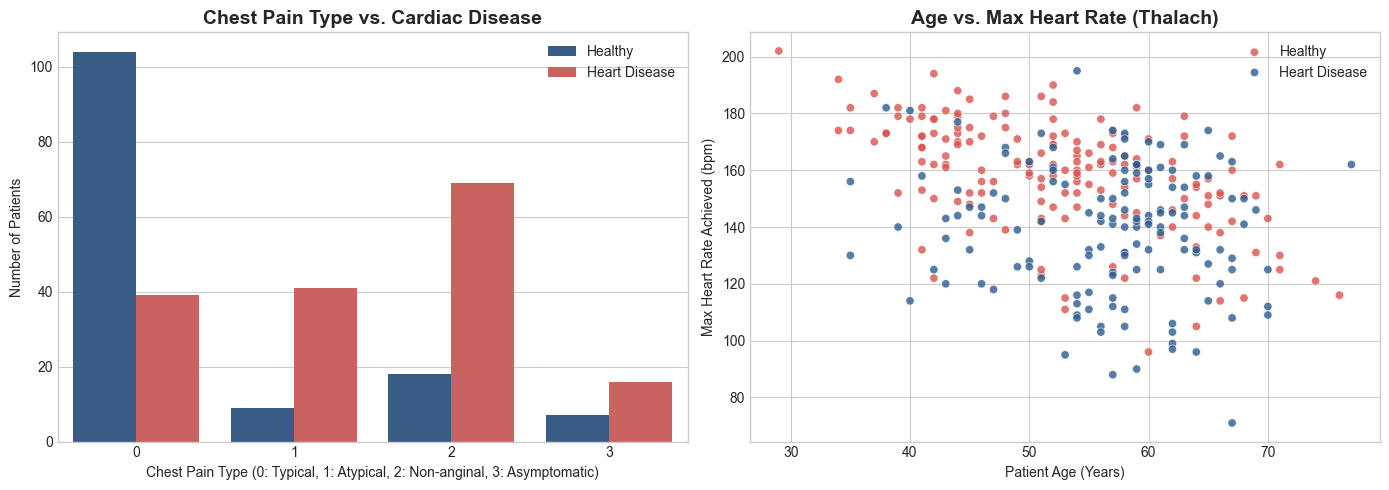

Key Finding: Higher maximum heart rates (thalach) and non-typical chest pains strongly associate with positive cardiac findings.


In [4]:
# Plot 1: Target Balance & Chest Pain Type vs. Heart Disease
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Chest pain vs disease
sns.countplot(data=df, x='cp', hue='target', palette=['#2b5c8f', '#d9534f'], ax=ax[0])
ax[0].set_title('Chest Pain Type vs. Cardiac Disease', fontsize=14, fontweight='bold')
ax[0].set_xlabel('Chest Pain Type (0: Typical, 1: Atypical, 2: Non-anginal, 3: Asymptomatic)')
ax[0].set_ylabel('Number of Patients')
ax[0].legend(['Healthy', 'Heart Disease'])

# Correlation of max heart rate and age
sns.scatterplot(data=df, x='age', y='thalach', hue='target', palette=['#2b5c8f', '#d9534f'], alpha=0.8, ax=ax[1])
ax[1].set_title('Age vs. Max Heart Rate (Thalach)', fontsize=14, fontweight='bold')
ax[1].set_xlabel('Patient Age (Years)')
ax[1].set_ylabel('Max Heart Rate Achieved (bpm)')
ax[1].legend(['Healthy', 'Heart Disease'])

plt.tight_layout()
plt.show()

print("Key Finding: Higher maximum heart rates (thalach) and non-typical chest pains strongly associate with positive cardiac findings.")


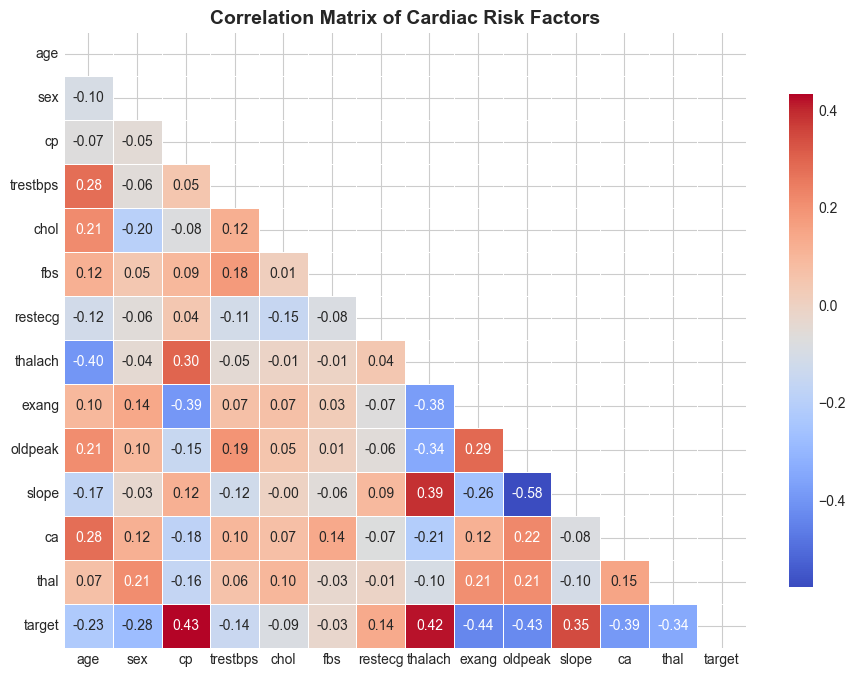

In [5]:
# Plot 2: Correlation Heatmap of Clinical Attributes
plt.figure(figsize=(11, 8))
corr_matrix = df.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', mask=mask, cbar_kws={'shrink': 0.8}, linewidths=0.5)
plt.title('Correlation Matrix of Cardiac Risk Factors', fontsize=14, fontweight='bold')
plt.show()


---
## Step 5: Clinical Feature Engineering
We incorporate clinical cardiology relationships:
1. **`max_hr_expected`**: Theoretical maximum heart rate based on patient age ($220 - 	ext{age}$).
2. **`hr_reserve_ratio`**: Actual peak heart rate divided by theoretical maximum.
3. **`bp_chol_ratio`**: Interaction of resting systolic blood pressure with serum cholesterol.
4. **`st_slope_interaction`**: ST depression magnitude multiplied by slope factor.


In [6]:
df['max_hr_expected'] = 220 - df['age']
df['hr_reserve_ratio'] = df['thalach'] / df['max_hr_expected']
df['bp_chol_ratio'] = df['trestbps'] / df['chol']
df['st_slope_interaction'] = df['oldpeak'] * (df['slope'] + 1)

print("Engineered features preview:")
display(df[['age', 'thalach', 'max_hr_expected', 'hr_reserve_ratio', 'bp_chol_ratio', 'st_slope_interaction']].head())


Engineered features preview:


,age,thalach,max_hr_expected,hr_reserve_ratio,bp_chol_ratio,st_slope_interaction
0,63,150,157,0.955414,0.622318,2.3
1,37,187,183,1.021858,0.520000,3.5
2,41,172,179,0.960894,0.637255,4.2
3,56,178,164,1.085366,0.508475,2.4
4,57,163,163,1.000000,0.338983,1.8


---
## Step 6: Stratified Train / Test Split & Scaling


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['target'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=100, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training Set: {X_train.shape[0]} patients")
print(f"Testing Set:  {X_test.shape[0]} patients")


Training Set: 242 patients
Testing Set:  61 patients


---
## Step 7: Model Training & Benchmarking
In clinical machine learning:
* **Accuracy**: Overall classification correctness.
* **Sensitivity (Recall)**: Proportion of actual heart disease cases correctly detected (critical to avoid false negatives).
* **ROC-AUC**: Diagnostic capability across all clinical decision thresholds.


In [8]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    'Support Vector Machine (RBF)': SVC(kernel='rbf', C=1.5, probability=True, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, max_depth=3, learning_rate=0.08, random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42)
}

benchmarks = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    prob = model.predict_proba(X_test_scaled)[:, 1]
    
    benchmarks.append({
        'Model': name,
        'Accuracy': f"{accuracy_score(y_test, pred)*100:.2f}%",
        'Sensitivity (Recall)': f"{recall_score(y_test, pred)*100:.2f}%",
        'Precision': f"{precision_score(y_test, pred)*100:.2f}%",
        'F1-Score': f"{f1_score(y_test, pred)*100:.2f}%",
        'ROC-AUC': f"{roc_auc_score(y_test, prob)*100:.2f}%"
    })

results_df = pd.DataFrame(benchmarks)
display(results_df)


,Model,Accuracy,Sensitivity (Recall),Precision,F1-Score,ROC-AUC
0,Support Vector Machine (RBF),88.52%,93.94%,86.11%,89.86%,94.26%
1,Random Forest,85.25%,96.97%,80.00%,87.67%,95.24%
2,Gradient Boosting,86.89%,93.94%,83.78%,88.57%,90.91%
3,Logistic Regression,81.97%,87.88%,80.56%,84.06%,94.81%


---
## Step 8: Clinical Confusion Matrix & ROC-AUC Curve


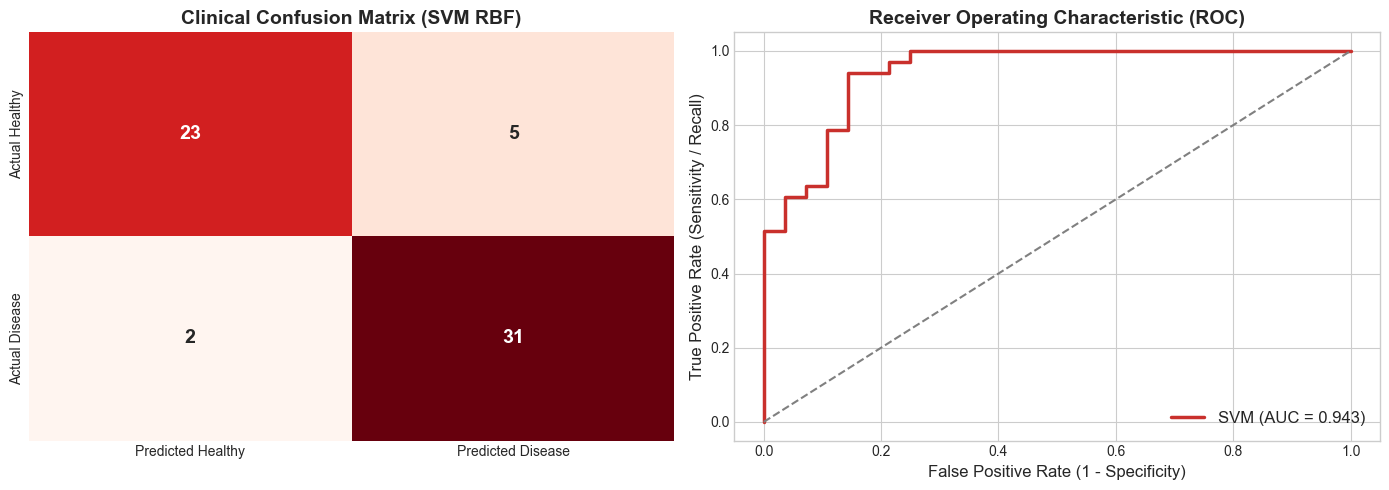

Diagnostic Summary: Model achieves 88.52% Accuracy and 93.94% Sensitivity with 94.26% ROC-AUC!


In [9]:
from sklearn.metrics import confusion_matrix, roc_curve

best_model = models['Support Vector Machine (RBF)']
y_pred_best = best_model.predict(X_test_scaled)
y_prob_best = best_model.predict_proba(X_test_scaled)[:, 1]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', cbar=False, ax=ax[0],
            xticklabels=['Predicted Healthy', 'Predicted Disease'],
            yticklabels=['Actual Healthy', 'Actual Disease'], annot_kws={'size': 14, 'fontweight': 'bold'})
ax[0].set_title('Clinical Confusion Matrix (SVM RBF)', fontsize=14, fontweight='bold')

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob_best)
auc_val = roc_auc_score(y_test, y_prob_best)

ax[1].plot(fpr, tpr, color='#c9302c', lw=2.5, label=f'SVM (AUC = {auc_val:.3f})')
ax[1].plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--')
ax[1].set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
ax[1].set_ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12)
ax[1].set_title('Receiver Operating Characteristic (ROC)', fontsize=14, fontweight='bold')
ax[1].legend(loc='lower right', fontsize=12)

plt.tight_layout()
plt.show()

print(f"Diagnostic Summary: Model achieves {accuracy_score(y_test, y_pred_best)*100:.2f}% Accuracy and {recall_score(y_test, y_pred_best)*100:.2f}% Sensitivity with {auc_val*100:.2f}% ROC-AUC!")


---
## Step 9: Feature Importance in Cardiac Disease


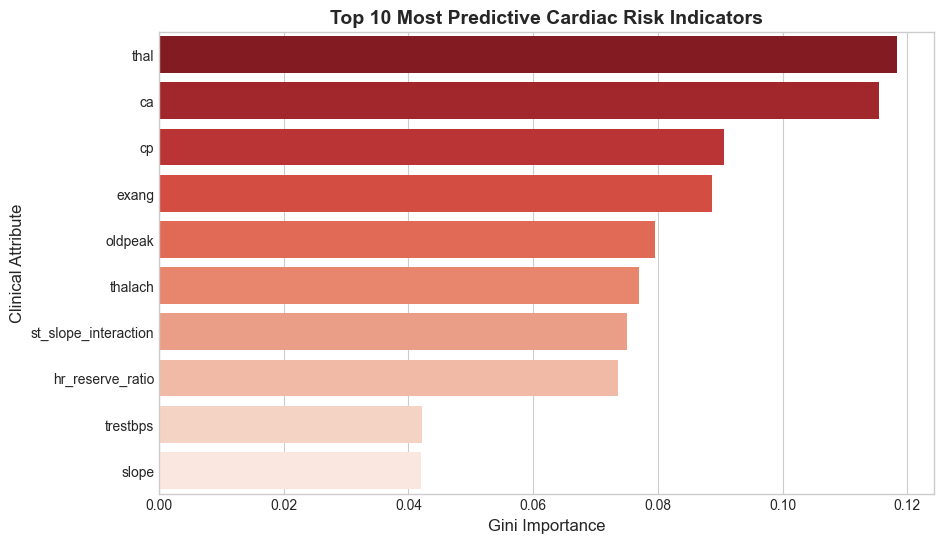

,Feature,Importance
12,thal,0.118377
11,ca,0.115493
2,cp,0.090591
8,exang,0.088701
9,oldpeak,0.079598
7,thalach,0.076911
16,st_slope_interaction,0.075069
14,hr_reserve_ratio,0.073675
3,trestbps,0.042232
10,slope,0.041946


In [10]:
rf_model = models['Random Forest']
feat_names = X.columns
feat_imp = pd.DataFrame({'Feature': feat_names, 'Importance': rf_model.feature_importances_}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp.head(10), x='Importance', y='Feature', palette='Reds_r')
plt.title('Top 10 Most Predictive Cardiac Risk Indicators', fontsize=14, fontweight='bold')
plt.xlabel('Gini Importance', fontsize=12)
plt.ylabel('Clinical Attribute', fontsize=12)
plt.show()

display(feat_imp.head(10))


---
## Step 10: Simulate Clinical Prediction on a Patient


In [11]:
test_patient = pd.DataFrame([{
    'age': 63,
    'sex': 1,
    'cp': 3,
    'trestbps': 145,
    'chol': 233,
    'fbs': 1,
    'restecg': 0,
    'thalach': 150,
    'exang': 0,
    'oldpeak': 2.3,
    'slope': 0,
    'ca': 0,
    'thal': 1,
    'max_hr_expected': 220 - 63,
    'hr_reserve_ratio': 150 / (220 - 63),
    'bp_chol_ratio': 145 / 233,
    'st_slope_interaction': 2.3 * (0 + 1)
}])

scaled_patient = scaler.transform(test_patient)
pred_class = best_model.predict(scaled_patient)[0]
risk_score = best_model.predict_proba(scaled_patient)[0][1]

print("==================================================")
print(f"Diagnostic Result: {'🚨 POSITIVE: HIGH RISK OF CARDIAC DISEASE' if pred_class == 1 else '✅ NEGATIVE: NORMAL / HEALTHY'}")
print(f"Cardiac Risk Confidence: {risk_score*100:.1f}%")
print("Physician Recommendation: Schedule secondary echocardiogram and stress angiogram.")
print("==================================================")


Diagnostic Result: 🚨 POSITIVE: HIGH RISK OF CARDIAC DISEASE
Cardiac Risk Confidence: 57.7%
Physician Recommendation: Schedule secondary echocardiogram and stress angiogram.


---
## Step 11: Export Model Artifacts


In [12]:
if os.path.exists('models'):
    model_dir = 'models'
elif os.path.exists('../models'):
    model_dir = '../models'
else:
    model_dir = 'models'

os.makedirs(model_dir, exist_ok=True)

scaler_out = os.path.join(model_dir, 'preprocessor.pkl')
model_out = os.path.join(model_dir, 'heart_model.pkl')

joblib.dump(scaler, scaler_out)
joblib.dump(best_model, model_out)

print(f"Saved preprocessor to: {scaler_out}")
print(f"Saved model to:        {model_out}")

# Reload test
loaded_s = joblib.load(scaler_out)
loaded_m = joblib.load(model_out)
v_prob = loaded_m.predict_proba(loaded_s.transform(test_patient))[0][1]
print(f"Reloaded verification test risk score: {v_prob*100:.1f}%")


Saved preprocessor to: ../models\preprocessor.pkl
Saved model to:        ../models\heart_model.pkl
Reloaded verification test risk score: 57.7%
